In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/anhtruong1/Air-quality-prediction/main/city_day.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [17]:
# Check the dataset size
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical information
print("\nStatistical Summary:")
display(df.describe())

# Check available cities
if "City" in df.columns:
    print("\nNumber of Cities:", df["City"].nunique())
    print("\nAvailable Cities:")
    print(df["City"].unique())

Dataset Shape: (29531, 16)

Column Names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000



Number of Cities: 26

Available Cities:
['Ahmedabad' 'Aizawl' 'Amaravati' 'Amritsar' 'Bengaluru' 'Bhopal'
 'Brajrajnagar' 'Chandigarh' 'Chennai' 'Coimbatore' 'Delhi' 'Ernakulam'
 'Gurugram' 'Guwahati' 'Hyderabad' 'Jaipur' 'Jorapokhar' 'Kochi' 'Kolkata'
 'Lucknow' 'Mumbai' 'Patna' 'Shillong' 'Talcher' 'Thiruvananthapuram'
 'Visakhapatnam']


In [18]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert the Date column to datetime format
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert pollution measurements and AQI to numeric values
numeric_columns = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene", "AQI"
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Remove rows where the target AQI is missing
df_clean = df_clean.dropna(subset=["AQI"])

# Remove invalid negative AQI values
df_clean = df_clean[df_clean["AQI"] >= 0]

# Display the cleaning results
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

display(df_clean.head())

Original Dataset Shape: (29531, 16)
Cleaned Dataset Shape: (24850, 16)

Missing Values After Cleaning:
City              0
Date              0
PM2.5           678
PM10           7086
NO              387
NO2             391
NOx            1857
NH3            6536
CO              445
SO2             605
O3              807
Benzene        3535
Toluene        5826
Xylene        15372
AQI               0
AQI_Bucket        0
dtype: int64


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
28,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor
29,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor
30,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe
31,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe
32,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe


AQI Category Distribution:
AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64


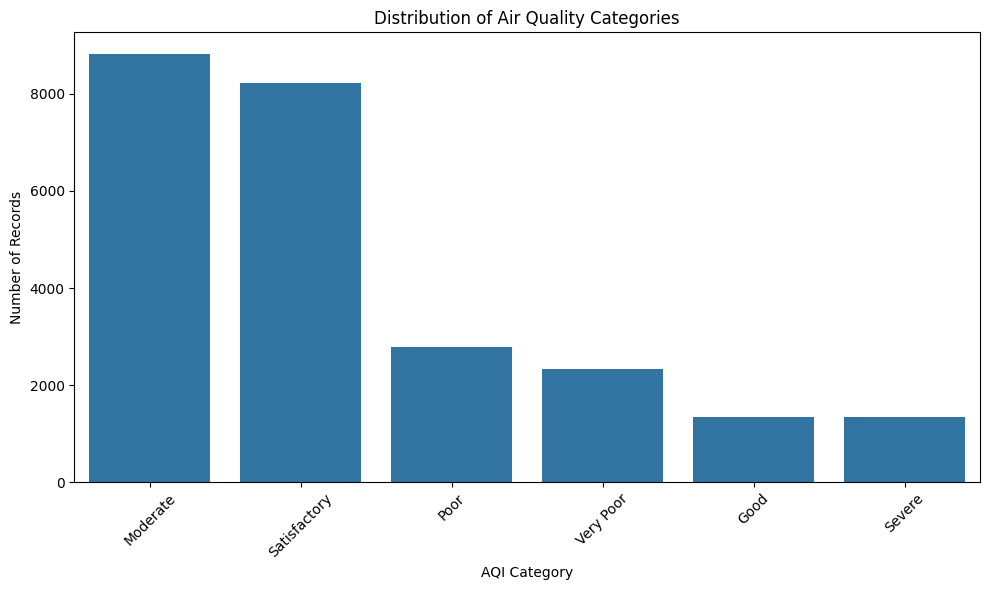

In [19]:
# Count the AQI categories
if "AQI_Bucket" in df_clean.columns:
    print("AQI Category Distribution:")
    print(df_clean["AQI_Bucket"].value_counts())

    plt.figure(figsize=(10, 6))
    sns.countplot(
        data=df_clean,
        x="AQI_Bucket",
        order=df_clean["AQI_Bucket"].value_counts().index
    )

    plt.title("Distribution of Air Quality Categories")
    plt.xlabel("AQI Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("AQI_Bucket column is unavailable.")

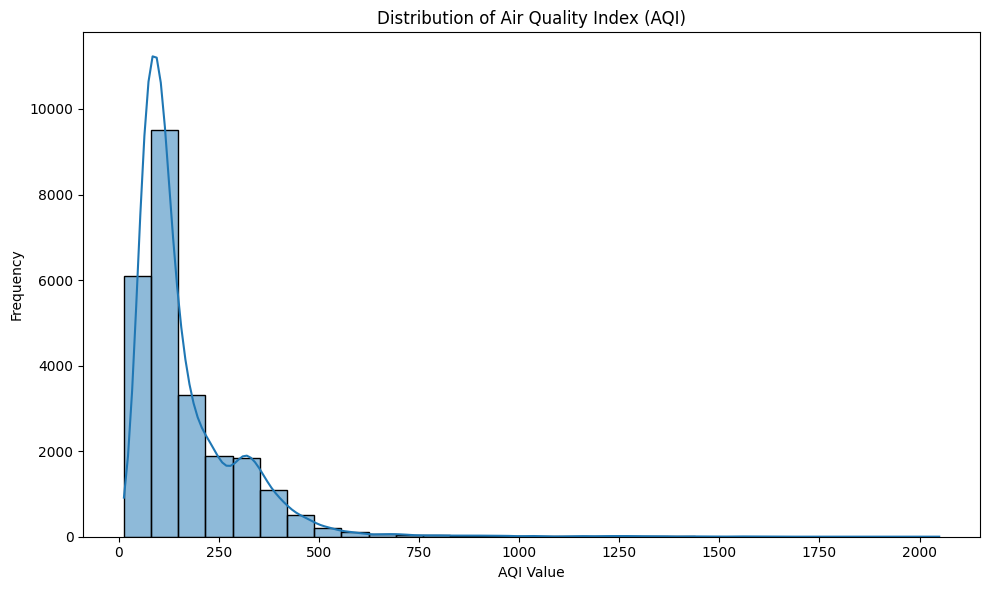

AQI Statistics:
Average AQI: 166.46
Minimum AQI: 13.0
Maximum AQI: 2049.0
Median AQI: 118.0


In [20]:
# Plot the distribution of AQI values
plt.figure(figsize=(10, 6))

sns.histplot(data=df_clean, x="AQI", bins=30, kde=True)

plt.title("Distribution of Air Quality Index (AQI)")
plt.xlabel("AQI Value")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

# Display important AQI statistics
print("AQI Statistics:")
print("Average AQI:", round(df_clean["AQI"].mean(), 2))
print("Minimum AQI:", df_clean["AQI"].min())
print("Maximum AQI:", df_clean["AQI"].max())
print("Median AQI:", df_clean["AQI"].median())

Average Pollution Levels:


,Average Level
PM10,118.45
PM2.5,67.48
O3,34.91
NO2,28.98
NH3,23.85
NO,17.62
SO2,14.36
CO,2.35


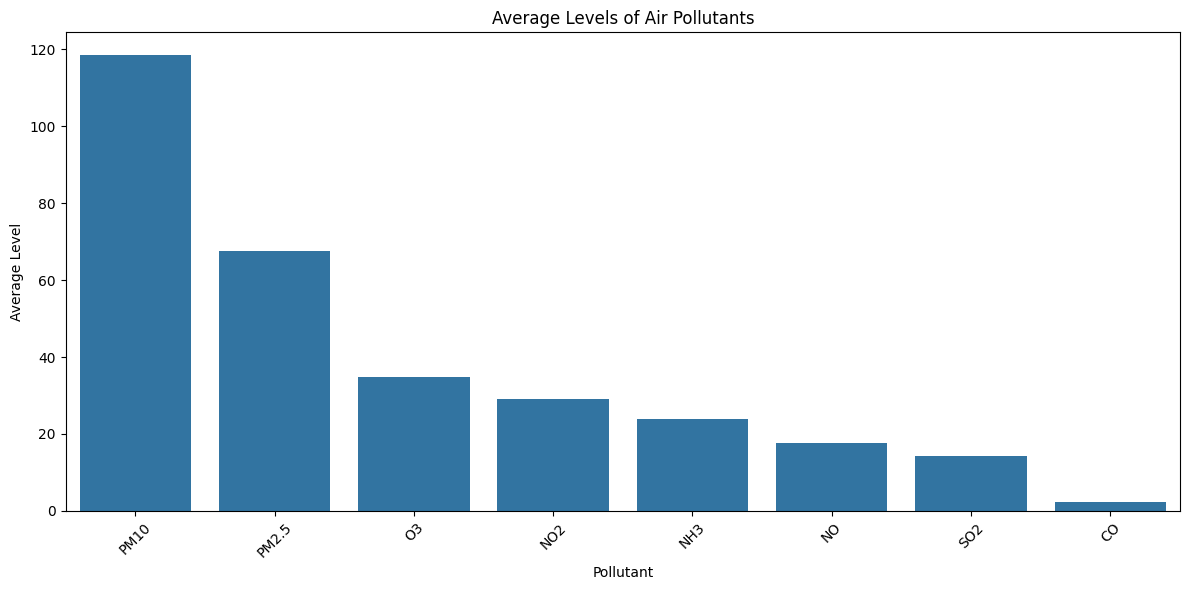

In [21]:
# Select available pollutant columns
pollutants = [
    "PM2.5", "PM10", "NO2", "SO2",
    "CO", "O3", "NO", "NH3"
]

available_pollutants = [
    col for col in pollutants if col in df_clean.columns
]

# Calculate average pollutant levels
pollution_averages = df_clean[available_pollutants].mean().sort_values(
    ascending=False
)

print("Average Pollution Levels:")
display(pollution_averages.to_frame(name="Average Level").round(2))

# Visualize average pollutant levels
plt.figure(figsize=(12, 6))

sns.barplot(
    x=pollution_averages.index,
    y=pollution_averages.values
)

plt.title("Average Levels of Air Pollutants")
plt.xlabel("Pollutant")
plt.ylabel("Average Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Average AQI by City:


,Average AQI
City,
Ahmedabad,452.12
Delhi,259.49
Patna,240.78
Gurugram,225.12
Lucknow,217.97
Talcher,172.89
Jorapokhar,159.25
Brajrajnagar,150.28
Kolkata,140.57


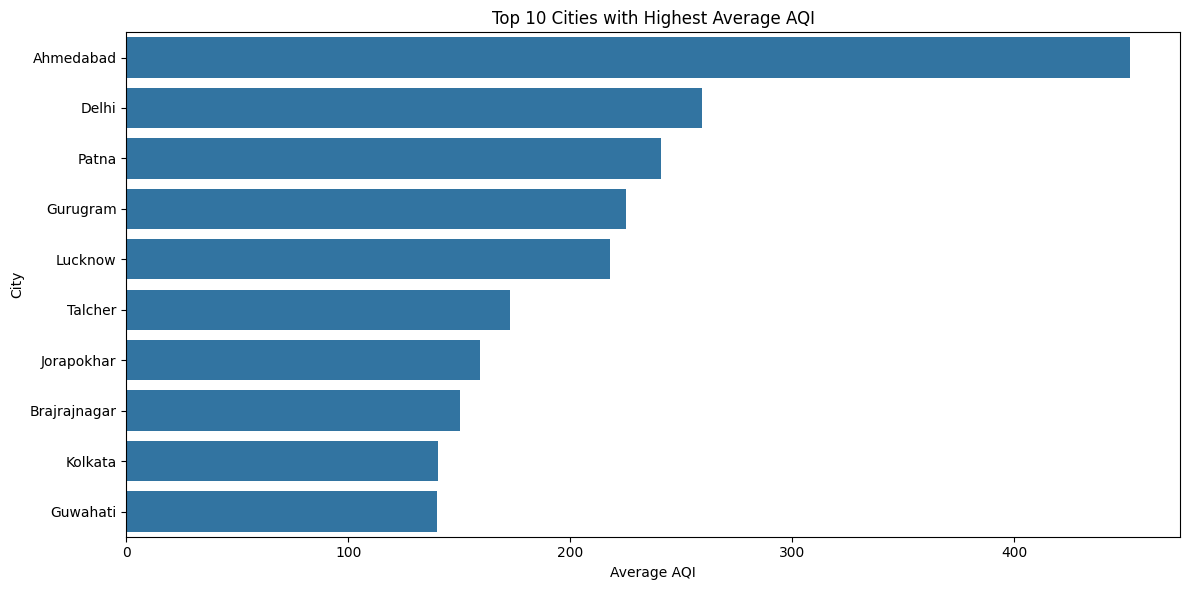

In [22]:
# Calculate average AQI for each city
city_aqi = (
    df_clean.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
)

print("Average AQI by City:")
display(city_aqi.to_frame(name="Average AQI").round(2))

# Select the 10 cities with the highest average AQI
top_10_cities = city_aqi.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index
)

plt.title("Top 10 Cities with Highest Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()

Correlation Between Pollutants and AQI:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI
PM2.5,1.00,0.85,0.46,0.37,0.45,0.28,0.09,0.14,0.17,0.66
PM10,0.85,1.00,0.53,0.48,0.54,0.39,0.12,0.26,0.25,0.80
NO,0.46,0.53,1.00,0.49,0.80,0.18,0.22,0.19,0.02,0.45
NO2,0.37,0.48,0.49,1.00,0.63,0.24,0.37,0.43,0.30,0.54
NOx,0.45,0.54,0.80,0.63,1.00,0.16,0.25,0.26,0.10,0.49
NH3,0.28,0.39,0.18,0.24,0.16,1.00,0.11,-0.03,0.10,0.25
CO,0.09,0.12,0.22,0.37,0.25,0.11,1.00,0.51,0.04,0.68
SO2,0.14,0.26,0.19,0.43,0.26,-0.03,0.51,1.00,0.17,0.49
O3,0.17,0.25,0.02,0.30,0.10,0.10,0.04,0.17,1.00,0.20
AQI,0.66,0.80,0.45,0.54,0.49,0.25,0.68,0.49,0.20,1.00


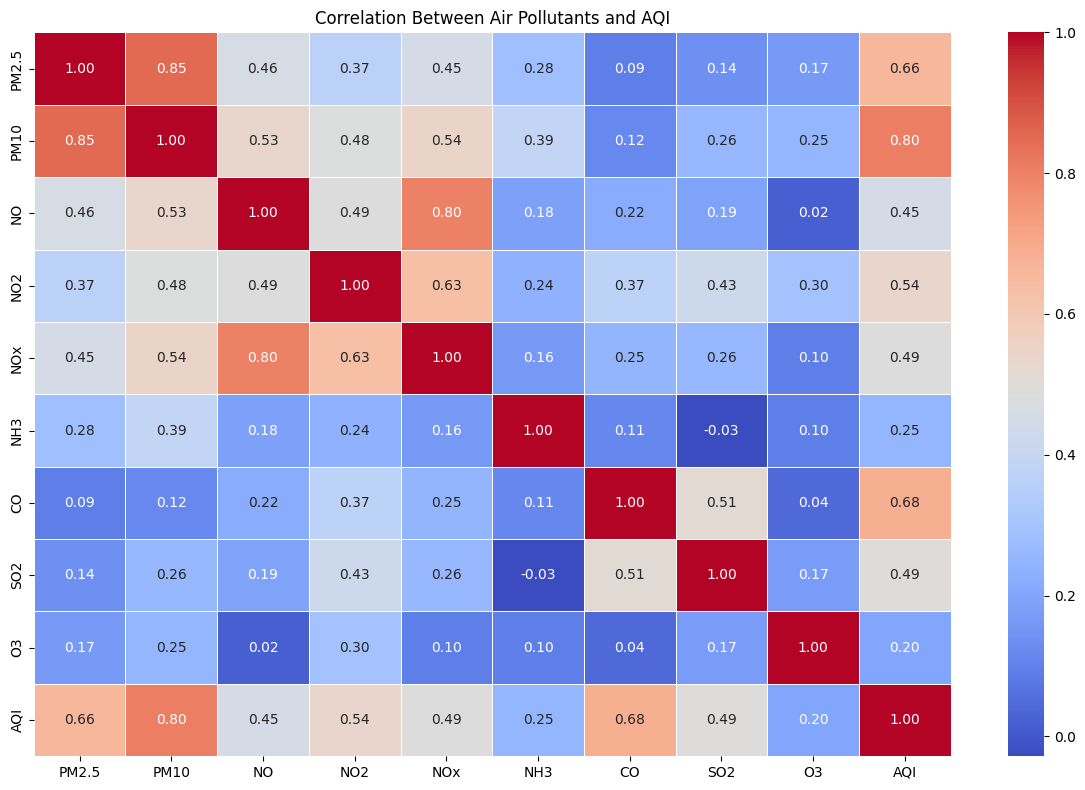

In [23]:
# Select pollutant columns available in the dataset
pollutant_columns = [
    col for col in [
        "PM2.5", "PM10", "NO", "NO2", "NOx",
        "NH3", "CO", "SO2", "O3"
    ]
    if col in df_clean.columns
]

# Include AQI in the correlation analysis
correlation_data = df_clean[pollutant_columns + ["AQI"]]

# Calculate correlations
correlation_matrix = correlation_data.corr()

print("Correlation Between Pollutants and AQI:")
display(correlation_matrix.round(2))

# Visualize correlations using a heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Air Pollutants and AQI")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Select pollutant features available in the dataset
candidate_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3"
]

features = [
    col for col in candidate_features
    if col in df_clean.columns
]

# Create input features and target
X = df_clean[features].copy()
y = df_clean["AQI"].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove features that contain no valid values
X = X.dropna(axis=1, how="all")

# Update the feature list
features = X.columns.tolist()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Fill missing values using training data only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=features,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=features,
    index=X_test.index
)

print("Selected Features:", features)
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nData preparation completed successfully!")

Selected Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']
Training Data Shape: (19880, 9)
Testing Data Shape: (4970, 9)

Data preparation completed successfully!


In [25]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("AQI Prediction Model Trained Successfully!")

AQI Prediction Model Trained Successfully!


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict AQI for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print("AQI Prediction Model Evaluation")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

AQI Prediction Model Evaluation
-----------------------------------
Mean Absolute Error (MAE): 20.95
Mean Squared Error (MSE): 1641.66
Root Mean Squared Error (RMSE): 40.52
R² Score: 0.9103


Actual vs Predicted AQI:


,Actual AQI,Predicted AQI,Prediction Error
0,141.0,96.70,44.30
1,209.0,212.02,-3.02
2,111.0,100.45,10.55
3,124.0,139.43,-15.43
4,81.0,78.25,2.75
5,54.0,67.25,-13.25
6,74.0,62.07,11.93
7,99.0,110.64,-11.64
8,97.0,131.84,-34.84
9,60.0,58.90,1.10


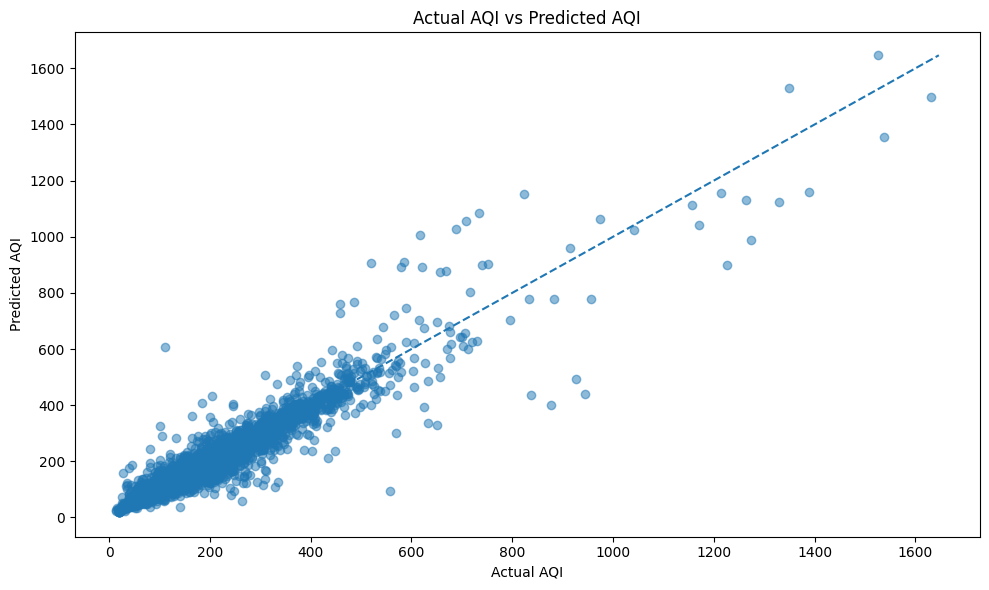

In [27]:
# Create a comparison table
comparison = pd.DataFrame({
    "Actual AQI": y_test.values,
    "Predicted AQI": y_pred
})

# Calculate the prediction error
comparison["Prediction Error"] = (
    comparison["Actual AQI"] - comparison["Predicted AQI"]
)

print("Actual vs Predicted AQI:")
display(comparison.head(10).round(2))

# Plot actual versus predicted AQI
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Add a reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual AQI vs Predicted AQI")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.tight_layout()
plt.show()

Pollutant Feature Importance:


,Pollutant,Importance
0,PM2.5,0.4939
6,CO,0.3716
2,NO,0.0383
1,PM10,0.0374
8,O3,0.0164
4,NOx,0.0145
7,SO2,0.0131
3,NO2,0.0107
5,NH3,0.0040


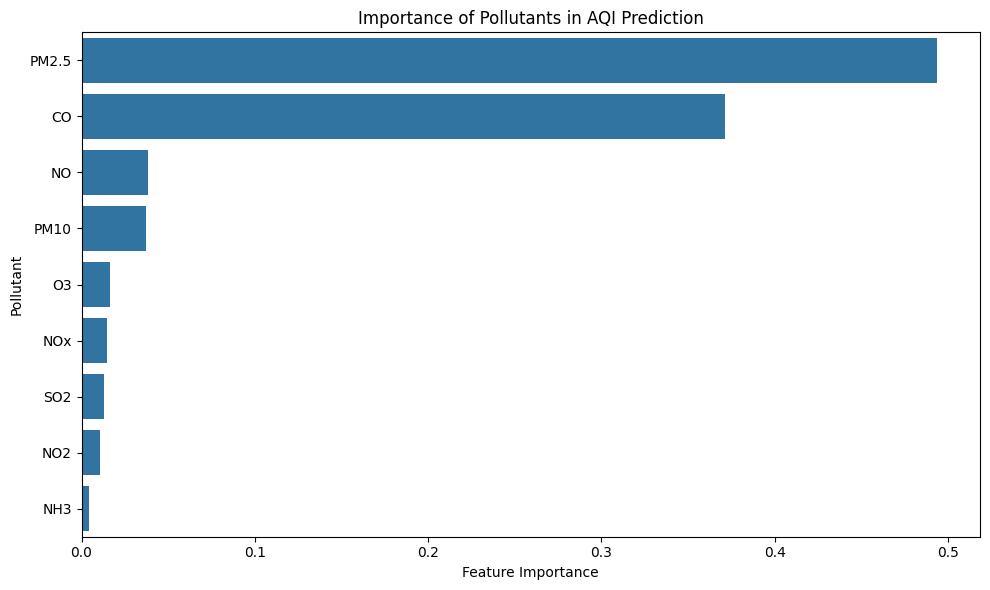

In [28]:
# Get feature importance from the trained model
importance_df = pd.DataFrame({
    "Pollutant": features,
    "Importance": model.feature_importances_
})

# Sort pollutants by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Pollutant Feature Importance:")
display(importance_df.round(4))

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Pollutant"
)

plt.title("Importance of Pollutants in AQI Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Pollutant")
plt.tight_layout()
plt.show()

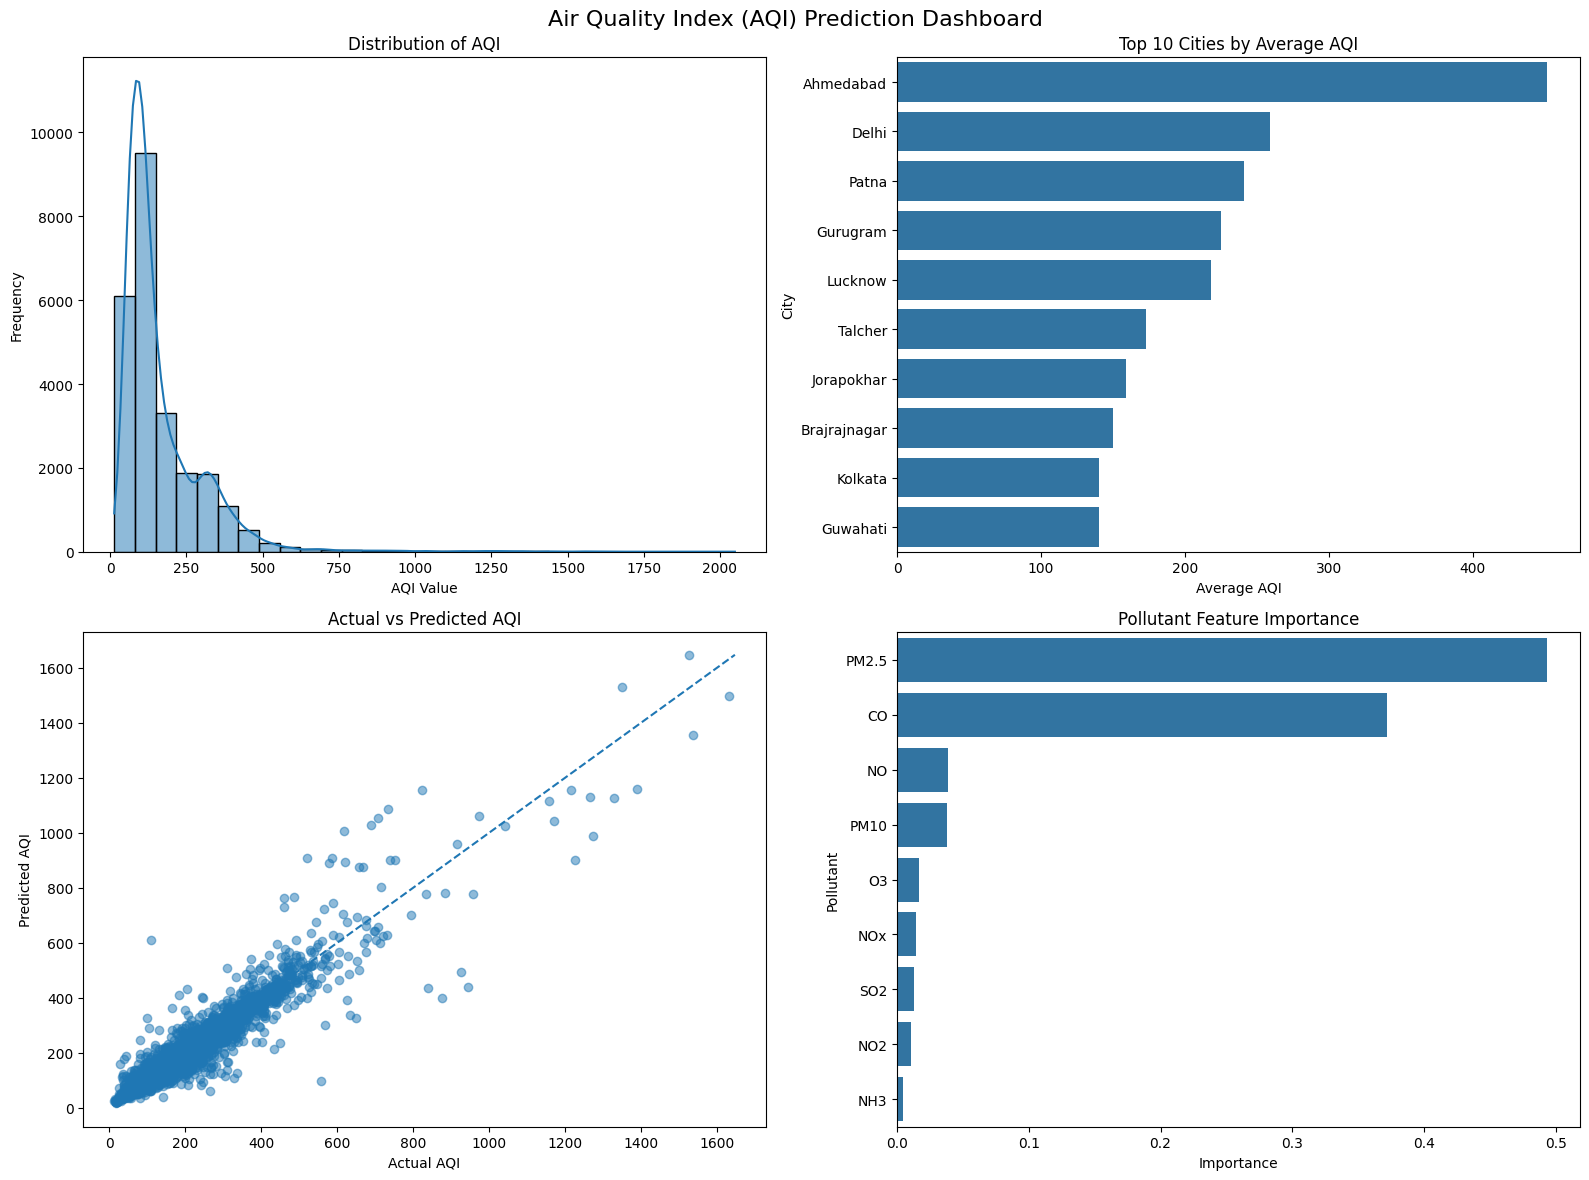

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of AQI values
sns.histplot(
    data=df_clean,
    x="AQI",
    bins=30,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of AQI")
axes[0, 0].set_xlabel("AQI Value")
axes[0, 0].set_ylabel("Frequency")

# 2. Average AQI of the 10 most polluted cities
sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 10 Cities by Average AQI")
axes[0, 1].set_xlabel("Average AQI")
axes[0, 1].set_ylabel("City")

# 3. Actual versus predicted AQI
axes[1, 0].scatter(y_test, y_pred, alpha=0.5)

axes[1, 0].plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
axes[1, 0].set_title("Actual vs Predicted AQI")
axes[1, 0].set_xlabel("Actual AQI")
axes[1, 0].set_ylabel("Predicted AQI")

# 4. Pollutant importance
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Pollutant",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Pollutant Feature Importance")
axes[1, 1].set_xlabel("Importance")
axes[1, 1].set_ylabel("Pollutant")

fig.suptitle("Air Quality Index (AQI) Prediction Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

In [30]:
# Calculate project statistics
total_records = len(df_clean)
total_cities = df_clean["City"].nunique()
average_aqi = df_clean["AQI"].mean()
minimum_aqi = df_clean["AQI"].min()
maximum_aqi = df_clean["AQI"].max()

# Identify the most important pollutant
most_important_pollutant = importance_df.iloc[0]["Pollutant"]

# Display project summary
print("=" * 50)
print("AQI PREDICTION - PROJECT SUMMARY")
print("=" * 50)

print(f"\nTotal Records Analyzed: {total_records:,}")
print(f"Number of Cities: {total_cities}")
print(f"Average AQI: {average_aqi:.2f}")
print(f"Minimum AQI: {minimum_aqi:.2f}")
print(f"Maximum AQI: {maximum_aqi:.2f}")

print("\nMODEL PERFORMANCE")
print("-" * 30)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

print("\nFEATURE IMPORTANCE")
print("-" * 30)
print(f"Most Important Pollutant: {most_important_pollutant}")

print("\nTECHNOLOGIES USED")
print("-" * 30)
print("Python, Pandas, NumPy, Matplotlib,")
print("Seaborn, and Scikit-learn")

print("\nProject Status: Analysis Completed")
print("=" * 50)

AQI PREDICTION - PROJECT SUMMARY

Total Records Analyzed: 24,850
Number of Cities: 26
Average AQI: 166.46
Minimum AQI: 13.00
Maximum AQI: 2049.00

MODEL PERFORMANCE
------------------------------
Mean Absolute Error (MAE): 20.95
Root Mean Squared Error (RMSE): 40.52
R² Score: 0.9103

FEATURE IMPORTANCE
------------------------------
Most Important Pollutant: PM2.5

TECHNOLOGIES USED
------------------------------
Python, Pandas, NumPy, Matplotlib,
Seaborn, and Scikit-learn

Project Status: Analysis Completed


# Conclusion

The AQI Prediction project analyzed air pollution data and developed a machine learning model to predict the Air Quality Index (AQI).

## Key Activities

1. Loaded and explored air quality data from Indian cities.
2. Cleaned the dataset and handled missing values.
3. Analyzed AQI distributions and pollution levels.
4. Compared average AQI values across cities.
5. Studied correlations between pollutants and AQI.
6. Prepared the data for machine learning.
7. Trained a Random Forest Regression model.
8. Evaluated the model using MAE, MSE, RMSE, and R² score.
9. Compared actual AQI values with predicted values.
10. Analyzed pollutant feature importance.
11. Created visualizations and an AQI prediction dashboard.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## Final Outcome

The project demonstrates how machine learning can be used to estimate AQI values from air pollutant measurements. The evaluation metrics and visualizations help assess the model's performance.

## Limitation

The model's predictions depend on the quality and coverage of the dataset. They should not be treated as official or real-time AQI measurements.

## Future Improvements

- Test additional machine learning models.
- Use time-based validation to evaluate predictions on future dates.
- Include more recent air quality data.
- Develop an interactive application for AQI prediction.